# Mall Shopper Profiling
Clustering 200 mall customers into shopper personas using K-Means, Agglomerative Clustering and DBSCAN.

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.optimize import linear_sum_assignment
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.neighbors import NearestNeighbors
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

warnings.filterwarnings('ignore')
sns.set_style('whitegrid')
VIS = '../visuals/'

def save(name):
    plt.tight_layout()
    plt.savefig(VIS + name, dpi=120, bbox_inches='tight')
    plt.show()

## Step 1: Data Loading and EDA
### 1.1 Load and inspect

In [2]:
df = pd.read_csv('../dataset/Mall_Customers.csv')
print(df.shape)
df.info()
df.head(10)

(200, 5)
<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype
---  ------                  --------------  -----
 0   CustomerID              200 non-null    int64
 1   Gender                  200 non-null    str  
 2   Age                     200 non-null    int64
 3   Annual Income (k$)      200 non-null    int64
 4   Spending Score (1-100)  200 non-null    int64
dtypes: int64(4), str(1)
memory usage: 7.9 KB


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
5,6,Female,22,17,76
6,7,Female,35,18,6
7,8,Female,23,18,94
8,9,Male,64,19,3
9,10,Female,30,19,72


In [3]:
df = df.rename(columns={'Genre': 'Gender', 'Annual Income (k$)': 'AnnualIncome', 'Spending Score (1-100)': 'SpendingScore'})
num_cols = ['Age', 'AnnualIncome', 'SpendingScore']
print(df.isnull().sum())
print()
print(df['Gender'].value_counts())

CustomerID       0
Gender           0
Age              0
AnnualIncome     0
SpendingScore    0
dtype: int64

Gender
Female    112
Male       88
Name: count, dtype: int64


The dataset has 200 rows and no missing values, so no cleaning is needed.

### 1.2 Univariate analysis

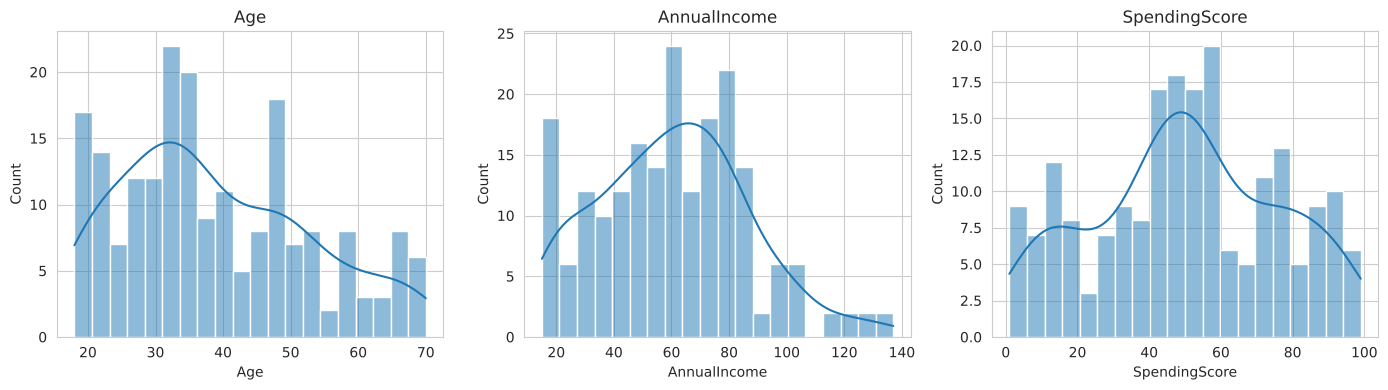

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(df[col], bins=20, kde=True, ax=ax)
    ax.set_title(col)
save('hist_distributions.png')

**Observations**
- Age: slightly right-skewed, most customers are between 20 and 50.
- AnnualIncome: close to bell-shaped, centred around 60k with a thin tail towards 137k.
- SpendingScore: spread across the full range with a large group near 50, and smaller groups at the low and high ends.

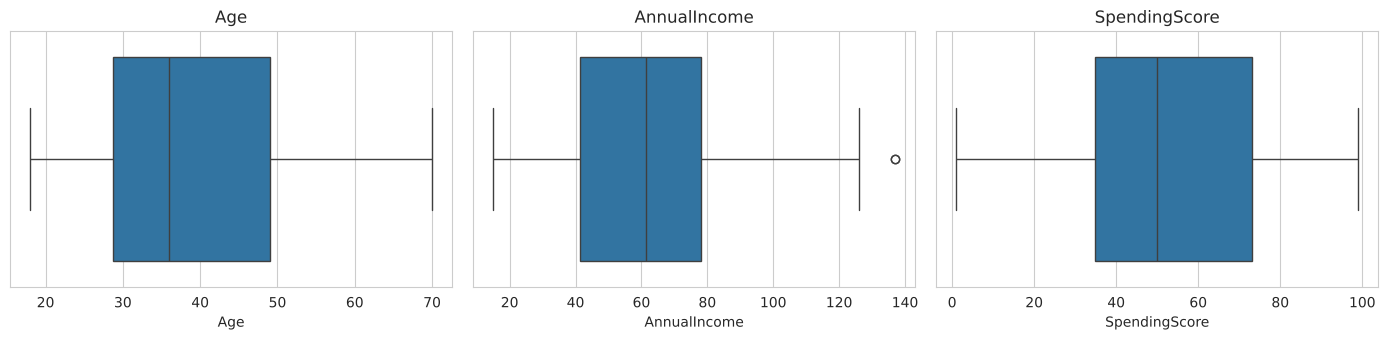

Age outliers: 0
AnnualIncome outliers: 2
SpendingScore outliers: 0


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)
save('boxplots.png')

for col in num_cols:
    q1, q3 = df[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    out = df[(df[col] < q1 - 1.5 * iqr) | (df[col] > q3 + 1.5 * iqr)]
    print(col, 'outliers:', len(out))

Only AnnualIncome has visible outliers (2 customers at the top end, around 137k). Age and SpendingScore have none. These two high earners are genuine customers, so they are kept.

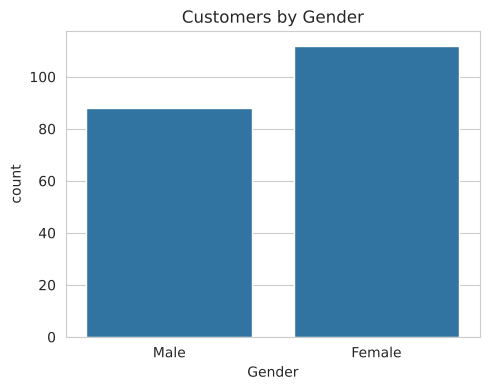

In [6]:
plt.figure(figsize=(5, 4))
sns.countplot(data=df, x='Gender')
plt.title('Customers by Gender')
save('gender_countplot.png')

There are 112 female and 88 male customers (56% / 44%). The dataset is reasonably balanced.

### 1.3 Bivariate analysis

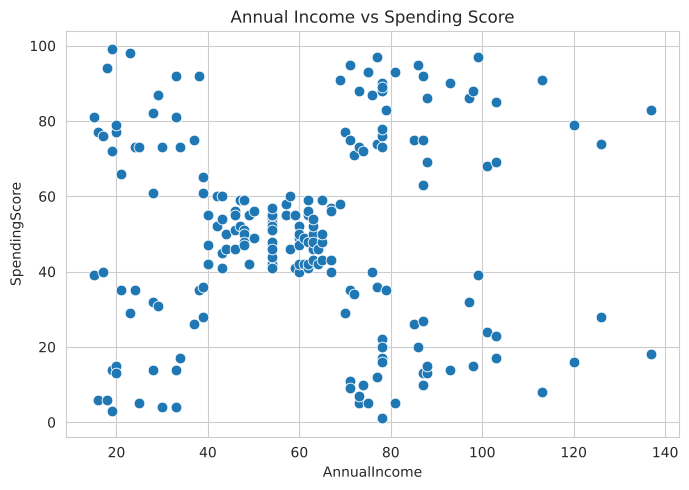

In [7]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='AnnualIncome', y='SpendingScore', s=60)
plt.title('Annual Income vs Spending Score')
save('scatter_income_spending.png')

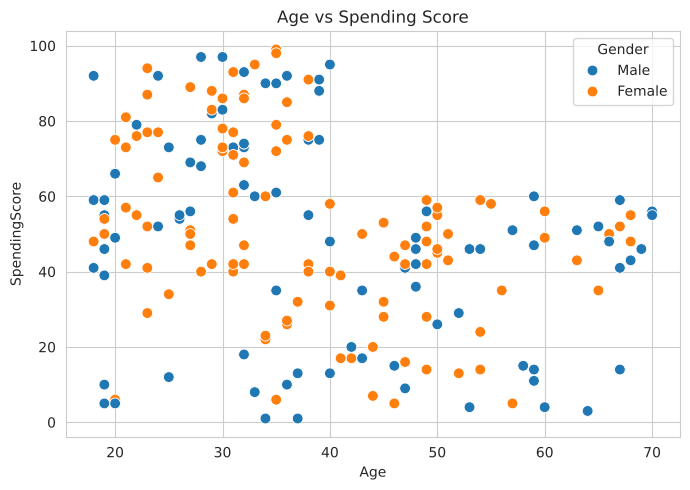

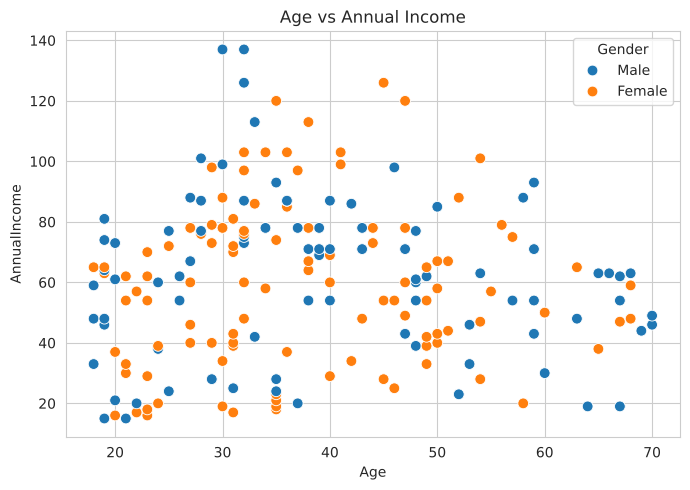

In [8]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='Age', y='SpendingScore', hue='Gender', s=60)
plt.title('Age vs Spending Score')
save('scatter_age_spending.png')

plt.figure(figsize=(7, 5))
sns.scatterplot(data=df, x='Age', y='AnnualIncome', hue='Gender', s=60)
plt.title('Age vs Annual Income')
save('scatter_age_income.png')

                 Age  AnnualIncome  SpendingScore
Age            1.000        -0.012         -0.327
AnnualIncome  -0.012         1.000          0.010
SpendingScore -0.327         0.010          1.000


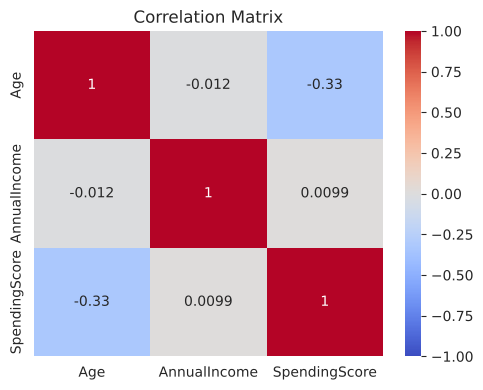

In [9]:
corr = df[num_cols].corr()
print(corr.round(3))
plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix')
save('correlation_heatmap.png')

**Observations**
- Income vs Spending shows clear separate blobs, not one trend line. Income and spending score are almost uncorrelated (0.01).
- Age and SpendingScore have a mild negative correlation (-0.33): younger customers tend to score higher on spending.
- Age and AnnualIncome show no relationship (-0.01).
- Gender does not separate the points in either Age plot.

### 1.4 Gender-wise summary

          Age  AnnualIncome  SpendingScore
Gender                                    
Female  38.10         59.25          51.53
Male    39.81         62.23          48.51


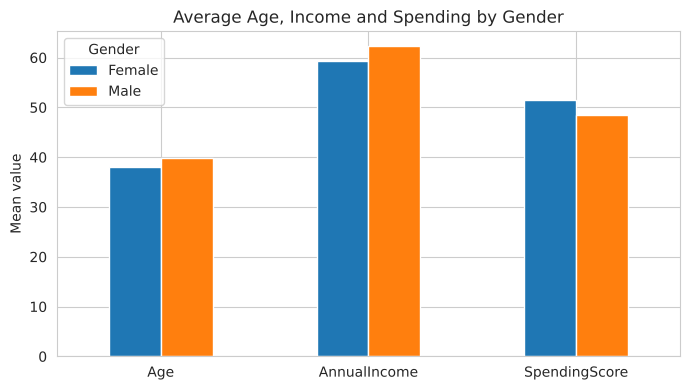

In [10]:
gender_summary = df.groupby('Gender')[num_cols].mean().round(2)
print(gender_summary)

gender_summary.T.plot(kind='bar', figsize=(7, 4))
plt.title('Average Age, Income and Spending by Gender')
plt.ylabel('Mean value')
plt.xticks(rotation=0)
save('gender_summary_bar.png')

Women have a slightly higher spending score (51.5 vs 48.5), while men have a slightly higher income (62.2k vs 59.3k) and are a little older (39.8 vs 38.1). The differences are small, so gender alone is not a strong basis for segmentation.

**What the Income vs Spending scatter shows before any algorithm is run**

Five groups are visible:
1. Centre: medium income, medium spending (the largest group).
2. Top right: high income, high spending.
3. Bottom right: high income, low spending.
4. Top left: low income, high spending.
5. Bottom left: low income, low spending.

## Step 2: Feature Engineering and Preprocessing
### 2.1 Encode gender

In [11]:
df['Gender_enc'] = df['Gender'].map({'Female': 0, 'Male': 1})
df[['Gender', 'Gender_enc']].head()

,Gender,Gender_enc
0,Male,1
1,Male,1
2,Female,0
3,Female,0
4,Female,0


### 2.2 New features

In [12]:
df['IncomeGroup'] = pd.qcut(df['AnnualIncome'], 3, labels=['Low', 'Medium', 'High'])
df['AgeGroup'] = pd.cut(df['Age'], bins=[17, 25, 40, 55, 100], labels=['Young', 'Adult', 'Middle-Aged', 'Senior'])
df['SpendingCategory'] = pd.cut(df['SpendingScore'], bins=[0, 33, 66, 100], labels=['Low', 'Medium', 'High'])

for col in ['IncomeGroup', 'AgeGroup', 'SpendingCategory']:
    print(df[col].value_counts())
    print()

IncomeGroup
Low       70
High      66
Medium    64
Name: count, dtype: int64

AgeGroup
Adult          84
Middle-Aged    49
Young          38
Senior         29
Name: count, dtype: int64

SpendingCategory
Medium    94
High      57
Low       49
Name: count, dtype: int64



IncomeGroup is nearly balanced (70 / 64 / 66) because it uses equal-frequency bins. AgeGroup is uneven: Adults are the largest group (84) and Seniors the smallest (29). SpendingCategory is also uneven, with 94 customers in Medium. These bins follow fixed ranges, so uneven counts are expected.

### 2.3 and 2.4 Feature sets and scaling

In [13]:
feat_2d = ['AnnualIncome', 'SpendingScore']
feat_5d = ['Age', 'AnnualIncome', 'SpendingScore', 'Gender_enc']
X_2d = df[feat_2d]
X_5d = df[feat_5d]

scaler_2d = StandardScaler()
X_2d_scaled = scaler_2d.fit_transform(X_2d)
scaler_5d = StandardScaler()
X_5d_scaled = scaler_5d.fit_transform(X_5d)

print(pd.DataFrame({'mean': X_2d_scaled.mean(axis=0), 'std': X_2d_scaled.std(axis=0)}, index=feat_2d).round(3))
print()
print(pd.DataFrame({'mean': X_5d_scaled.mean(axis=0), 'std': X_5d_scaled.std(axis=0)}, index=feat_5d).round(3))

               mean  std
AnnualIncome   -0.0  1.0
SpendingScore  -0.0  1.0

               mean  std
Age            -0.0  1.0
AnnualIncome   -0.0  1.0
SpendingScore  -0.0  1.0
Gender_enc      0.0  1.0


## Step 3: K-Means Clustering
### 3.1 Elbow method and silhouette score

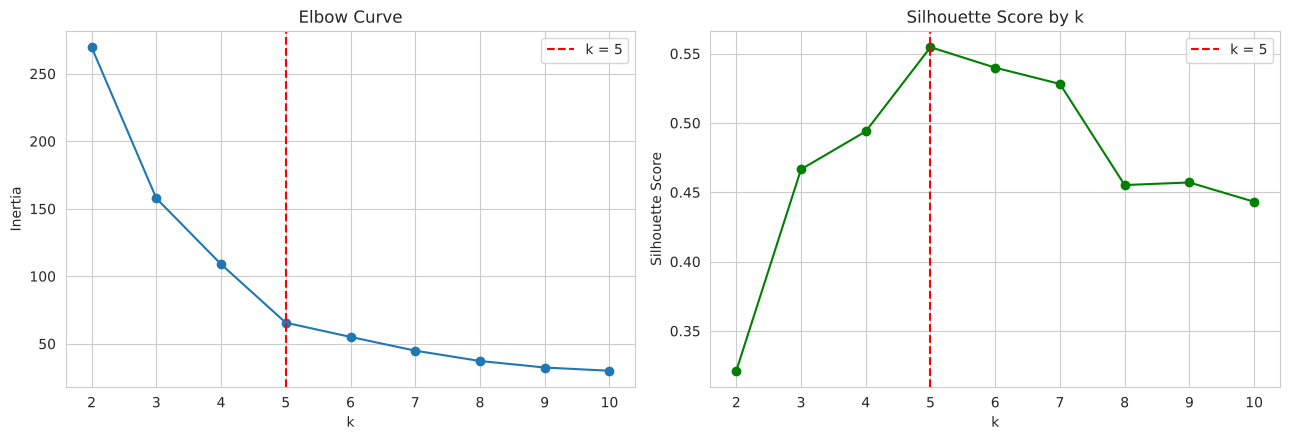

 k  Inertia  Silhouette
 2  269.691       0.321
 3  157.704       0.467
 4  108.921       0.494
 5   65.568       0.555
 6   55.057       0.540
 7   44.865       0.528
 8   37.228       0.455
 9   32.392       0.457
10   29.982       0.443


In [14]:
ks = list(range(2, 11))
inertias, sils = [], []
for k in ks:
    km = KMeans(n_clusters=k, init='k-means++', n_init=10, random_state=42).fit(X_2d_scaled)
    inertias.append(km.inertia_)
    sils.append(silhouette_score(X_2d_scaled, km.labels_))

k_opt = 5

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(ks, inertias, 'o-')
axes[0].axvline(k_opt, color='red', linestyle='--', label='k = 5')
axes[0].set_xlabel('k')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow Curve')
axes[0].legend()
axes[1].plot(ks, sils, 'o-', color='green')
axes[1].axvline(k_opt, color='red', linestyle='--', label='k = 5')
axes[1].set_xlabel('k')
axes[1].set_ylabel('Silhouette Score')
axes[1].set_title('Silhouette Score by k')
axes[1].legend()
save('kmeans_elbow_silhouette.png')

print(pd.DataFrame({'k': ks, 'Inertia': inertias, 'Silhouette': sils}).round(3).to_string(index=False))

**Choice: k = 5.** The inertia curve bends clearly at k = 5 and flattens after it. The silhouette score is highest at k = 5 (0.555) and drops for larger k. Both plots agree, and it matches the five groups seen in the scatter plot.

### 3.2 Final K-Means models (2D and 5D)

In [15]:
kmeans_2d = KMeans(n_clusters=k_opt, init='k-means++', n_init=20, max_iter=500, random_state=42).fit(X_2d_scaled)
kmeans_5d = KMeans(n_clusters=k_opt, init='k-means++', n_init=20, max_iter=500, random_state=42).fit(X_5d_scaled)
df['KMeans_Cluster'] = kmeans_2d.labels_
df['KMeans_5D_Cluster'] = kmeans_5d.labels_

sil_2d = silhouette_score(X_2d_scaled, kmeans_2d.labels_)
sil_5d = silhouette_score(X_5d_scaled, kmeans_5d.labels_)
print('Silhouette 2D:', round(sil_2d, 4))
print('Silhouette 5D:', round(sil_5d, 4))

Silhouette 2D: 0.5547
Silhouette 5D: 0.3144


The 2D model has a silhouette score of 0.555 against 0.314 for the 5D model. The 2D feature set gives much better separated clusters. Adding Age and Gender spreads customers out in directions where the groups overlap, which blurs the boundaries.

### 3.3 Visualise K-Means clusters

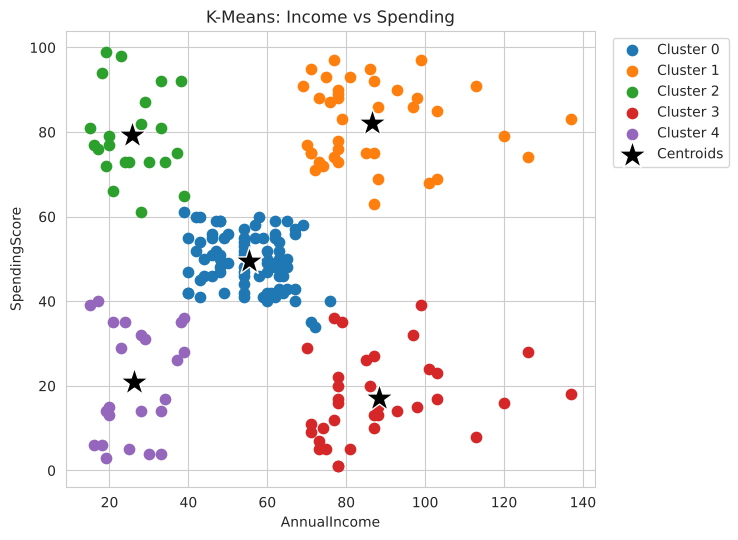

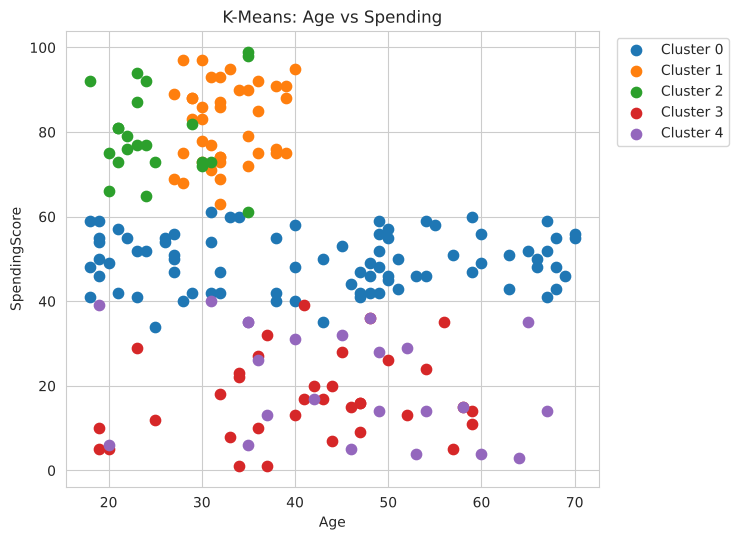

In [16]:
def cluster_scatter(col, x, y, title, fname, centers=None):
    plt.figure(figsize=(7.5, 5.5))
    for lab in sorted(df[col].unique()):
        sub = df[df[col] == lab]
        if lab == -1:
            plt.scatter(sub[x], sub[y], c='grey', marker='x', s=50, label='Noise')
        else:
            plt.scatter(sub[x], sub[y], s=55, label=f'Cluster {lab}')
    if centers is not None:
        plt.scatter(centers[:, 0], centers[:, 1], marker='*', s=450, c='black', edgecolors='white', label='Centroids')
    plt.xlabel(x)
    plt.ylabel(y)
    plt.title(title)
    plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    save(fname)

centers_2d = scaler_2d.inverse_transform(kmeans_2d.cluster_centers_)
cluster_scatter('KMeans_Cluster', 'AnnualIncome', 'SpendingScore', 'K-Means: Income vs Spending', 'kmeans_income_spending.png', centers_2d)
cluster_scatter('KMeans_Cluster', 'Age', 'SpendingScore', 'K-Means: Age vs Spending', 'kmeans_age_spending.png')

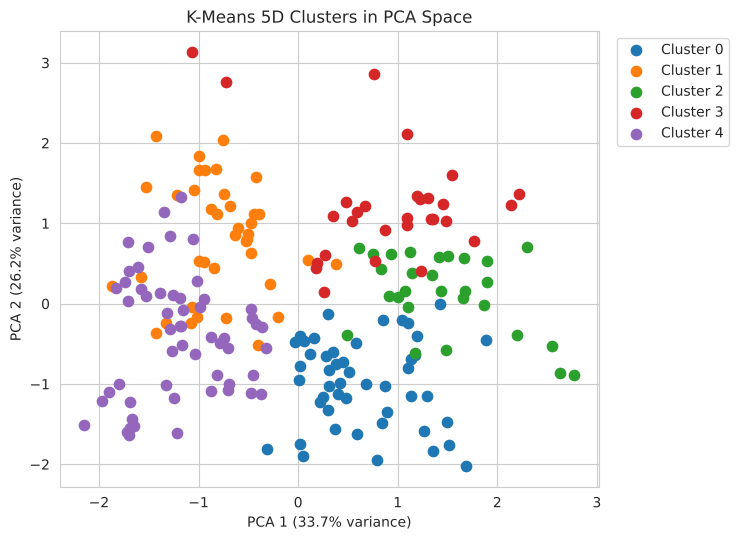

In [17]:
pca = PCA(n_components=2, random_state=42)
pcs = pca.fit_transform(X_5d_scaled)
var = pca.explained_variance_ratio_ * 100

plt.figure(figsize=(7.5, 5.5))
for lab in sorted(df['KMeans_5D_Cluster'].unique()):
    m = (df['KMeans_5D_Cluster'] == lab).values
    plt.scatter(pcs[m, 0], pcs[m, 1], s=55, label=f'Cluster {lab}')
plt.xlabel(f'PCA 1 ({var[0]:.1f}% variance)')
plt.ylabel(f'PCA 2 ({var[1]:.1f}% variance)')
plt.title('K-Means 5D Clusters in PCA Space')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
save('kmeans_5d_pca.png')

### 3.4 Profile the clusters

In [18]:
def make_profile(col):
    prof = df.groupby(col)[num_cols].mean().round(1)
    prof['Customers'] = df[col].value_counts().sort_index()
    return prof

def get_persona(income, score):
    if income >= 70 and score >= 60:
        return 'Big Spenders'
    if income >= 70 and score < 40:
        return 'Careful Spenders'
    if income < 45 and score >= 60:
        return 'Young Aspirers'
    if income < 45 and score < 40:
        return 'Budget Shoppers'
    return 'Average Shoppers'

km_profile = make_profile('KMeans_Cluster').sort_values('SpendingScore', ascending=False)
km_profile['Persona'] = [get_persona(r.AnnualIncome, r.SpendingScore) for r in km_profile.itertuples()]
display(km_profile)

gender_split = (pd.crosstab(df['KMeans_Cluster'], df['Gender'], normalize='index') * 100).round(1)
gender_split.columns = ['% Female', '% Male']
display(gender_split)

df['KMeans_Persona'] = df['KMeans_Cluster'].map(km_profile['Persona'].to_dict())

,Age,AnnualIncome,SpendingScore,Customers,Persona
KMeans_Cluster,,,,,
1,32.7,86.5,82.1,39,Big Spenders
2,25.3,25.7,79.4,22,Young Aspirers
0,42.7,55.3,49.5,81,Average Shoppers
4,45.2,26.3,20.9,23,Budget Shoppers
3,41.1,88.2,17.1,35,Careful Spenders


,% Female,% Male
KMeans_Cluster,,
0,59.3,40.7
1,53.8,46.2
2,59.1,40.9
3,45.7,54.3
4,60.9,39.1


**Personas**
- **Big Spenders** (Cluster 1, 39 customers): income about 86k and spending score 82. They earn well and spend freely, so they belong in premium brand zones (the Zara shopper).
- **Young Aspirers** (Cluster 2, 22 customers): average age 25, income about 26k but spending score 79. Young shoppers who spend beyond their income on trends.
- **Average Shoppers** (Cluster 0, 81 customers): income about 55k and spending score 50. The largest group and the core mid-market (the Westside shopper).
- **Budget Shoppers** (Cluster 4, 23 customers): income about 26k and spending score 21. Older and price-conscious, they respond to discounts and deals.
- **Careful Spenders** (Cluster 3, 35 customers): income about 88k but spending score only 17. They can afford more but spend little, so they are the biggest untapped opportunity.

Gender is fairly even in every cluster; Careful Spenders is the only group with more men (54%).

## Step 4: Agglomerative Hierarchical Clustering
### 4.1 Dendrogram

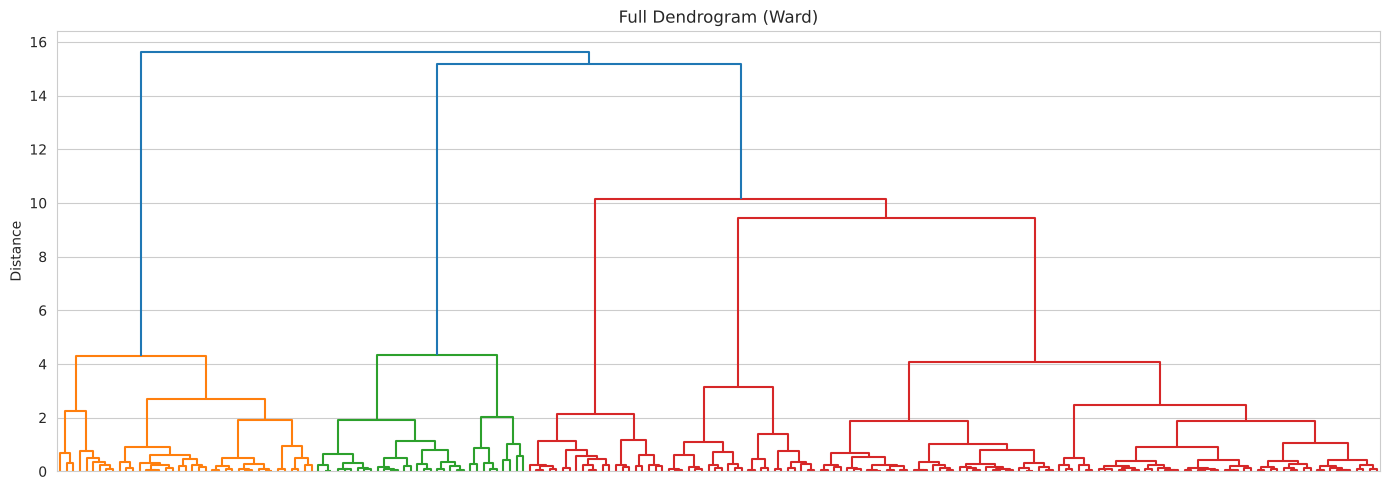

In [19]:
Z = linkage(X_2d_scaled, method='ward')

plt.figure(figsize=(14, 5))
dendrogram(Z, no_labels=True)
plt.title('Full Dendrogram (Ward)')
plt.ylabel('Distance')
save('dendrogram_full.png')

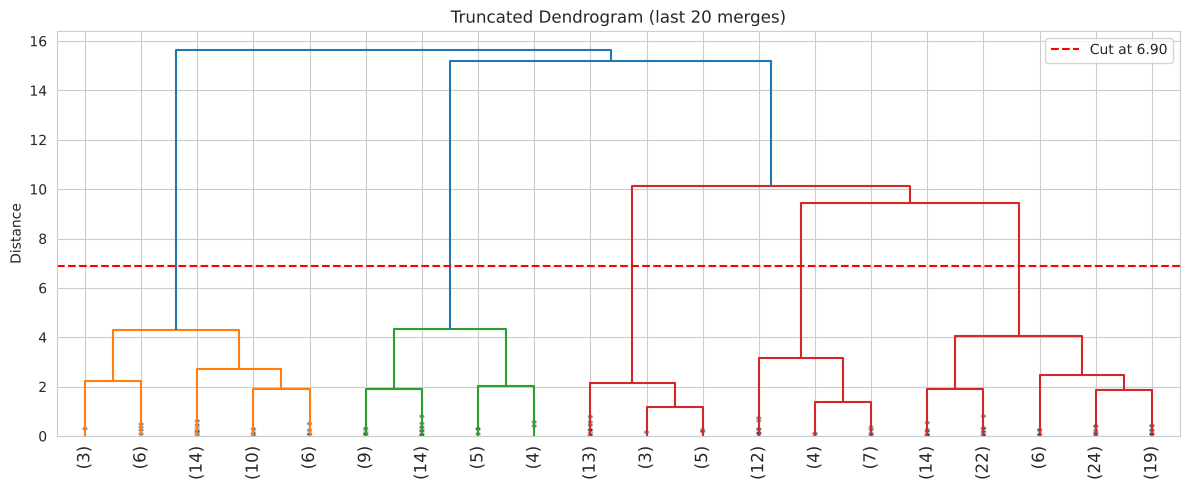

Cut distance: 6.9
Clusters: 5


In [20]:
heights = Z[:, 2]
n = len(X_2d_scaled)
gaps = {c: heights[n - c] - heights[n - c - 1] for c in range(3, 11)}
n_chosen = max(gaps, key=gaps.get)
cut_height = (heights[n - n_chosen] + heights[n - n_chosen - 1]) / 2

plt.figure(figsize=(12, 5))
dendrogram(Z, truncate_mode='lastp', p=20, leaf_rotation=90, show_contracted=True)
plt.axhline(cut_height, color='red', linestyle='--', label=f'Cut at {cut_height:.2f}')
plt.title('Truncated Dendrogram (last 20 merges)')
plt.ylabel('Distance')
plt.legend()
save('dendrogram_truncated.png')

print('Cut distance:', round(cut_height, 2))
print('Clusters:', n_chosen)

The cut is placed at a distance of **6.9**, inside the longest vertical gap between 3 and 10 clusters. This gives **5 clusters**, which matches K-Means.

### 4.2 Compare linkage methods

In [21]:
agg_labels, agg_sil = {}, {}
for link in ['ward', 'complete', 'average']:
    labels = AgglomerativeClustering(n_clusters=n_chosen, linkage=link).fit_predict(X_2d_scaled)
    agg_labels[link] = labels
    agg_sil[link] = silhouette_score(X_2d_scaled, labels)

print(pd.DataFrame({'Linkage': list(agg_sil.keys()), 'Silhouette': list(agg_sil.values())}).round(4).to_string(index=False))

best_link = max(agg_sil, key=agg_sil.get)
df['Agg_Cluster'] = agg_labels[best_link]
print('Best linkage:', best_link)

 Linkage  Silhouette
    ward      0.5538
complete      0.5531
 average      0.4794
Best linkage: ward


Ward (0.5538) and complete (0.5531) linkage score almost the same, while average linkage is clearly worse (0.4794). **Ward** is selected because it has the highest silhouette score.

### 4.3 Visualise and profile

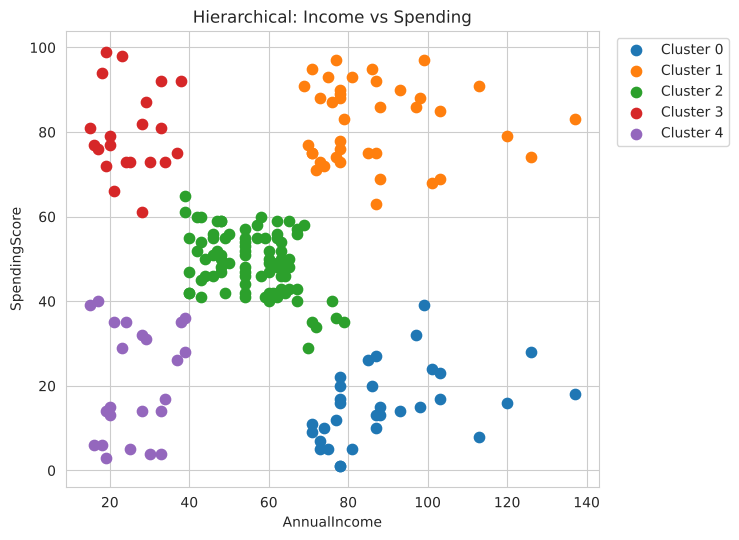

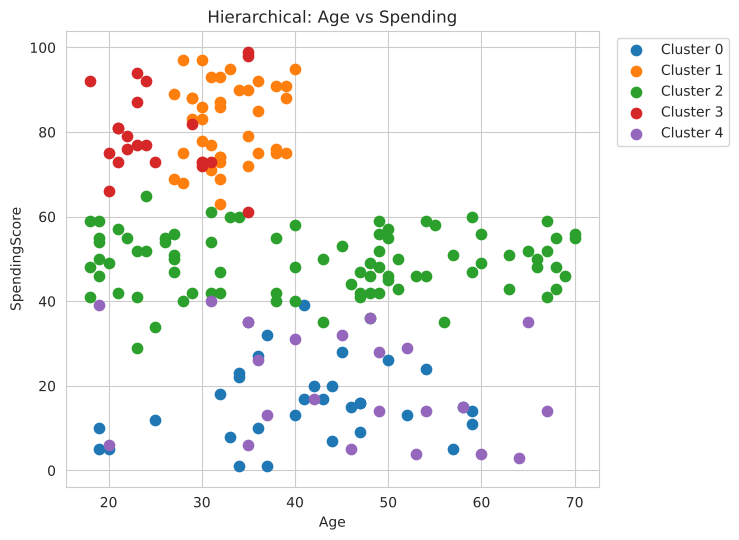

In [22]:
cluster_scatter('Agg_Cluster', 'AnnualIncome', 'SpendingScore', 'Hierarchical: Income vs Spending', 'agg_income_spending.png')
cluster_scatter('Agg_Cluster', 'Age', 'SpendingScore', 'Hierarchical: Age vs Spending', 'agg_age_spending.png')

In [23]:
agg_profile = make_profile('Agg_Cluster').sort_values('SpendingScore', ascending=False)
agg_profile['Persona'] = [get_persona(r.AnnualIncome, r.SpendingScore) for r in agg_profile.itertuples()]
display(agg_profile)

cont = pd.crosstab(df['KMeans_Cluster'], df['Agg_Cluster'])
rows, cols = linear_sum_assignment(-cont.values)
agreement = cont.values[rows, cols].sum() / len(df) * 100
print('K-Means vs Hierarchical agreement:', round(agreement, 1), '%')

,Age,AnnualIncome,SpendingScore,Customers,Persona
Agg_Cluster,,,,,
1,32.7,86.5,82.1,39,Big Spenders
3,25.3,25.1,80.0,21,Young Aspirers
2,42.5,55.8,49.1,85,Average Shoppers
4,45.2,26.3,20.9,23,Budget Shoppers
0,41.0,89.4,15.6,32,Careful Spenders


K-Means vs Hierarchical agreement: 98.0 %


The hierarchical clusters match the K-Means ones closely, with the same five personas and almost the same sizes and averages. **98.0%** of customers are assigned to the same group by both algorithms. Only a few customers on cluster borders differ.

## Step 5: DBSCAN Clustering
### 5.1 Choose epsilon with the k-NN distance plot

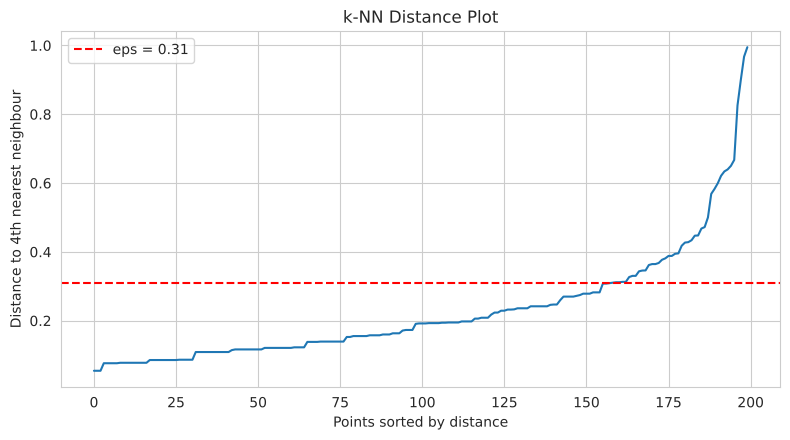

Chosen eps: 0.31


In [24]:
nn = NearestNeighbors(n_neighbors=4).fit(X_2d_scaled)
dist, _ = nn.kneighbors(X_2d_scaled)
kdist = np.sort(dist[:, -1])

x = np.arange(len(kdist))
start = np.array([0, kdist[0]])
end = np.array([x[-1], kdist[-1]])
direction = (end - start) / np.linalg.norm(end - start)
vec = np.column_stack([x, kdist]) - start
gap = np.abs(vec[:, 0] * direction[1] - vec[:, 1] * direction[0])
knee = gap.argmax()
optimal_eps = round(float(kdist[knee]), 2)

plt.figure(figsize=(8, 4.5))
plt.plot(x, kdist)
plt.axhline(optimal_eps, color='red', linestyle='--', label=f'eps = {optimal_eps}')
plt.xlabel('Points sorted by distance')
plt.ylabel('Distance to 4th nearest neighbour')
plt.title('k-NN Distance Plot')
plt.legend()
save('dbscan_knn_distance.png')

print('Chosen eps:', optimal_eps)

**Chosen eps = 0.31.** This is the point where the k-NN distance curve starts to rise sharply. Before it, points sit inside dense areas; after it, distances jump because points are isolated.

### 5.2 Train DBSCAN

In [25]:
db = DBSCAN(eps=optimal_eps, min_samples=4, metric='euclidean').fit(X_2d_scaled)
df['DBSCAN_Cluster'] = db.labels_
n_clusters = len(set(db.labels_)) - (1 if -1 in db.labels_ else 0)
n_noise = (db.labels_ == -1).sum()
print('Clusters:', n_clusters)
print('Noise points:', n_noise, f'({n_noise / len(df) * 100:.1f}%)')

Clusters: 7
Noise points: 19 (9.5%)


### 5.3 Hyperparameter grid

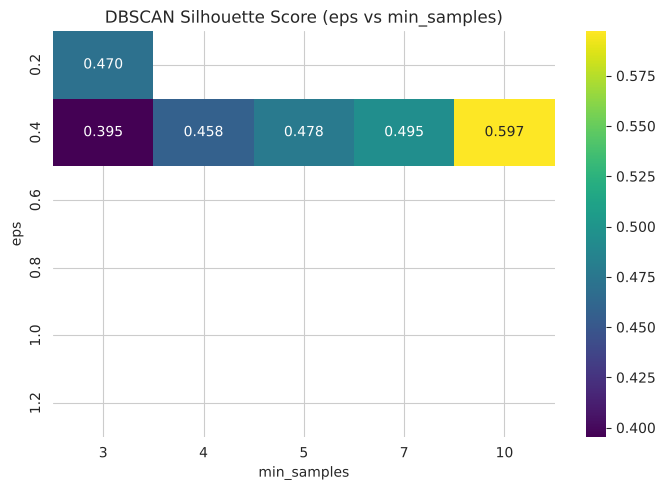

Best eps: 0.4 | Best min_samples: 10
 eps  min_samples  Clusters  Noise %  Silhouette
 0.4           10         4     25.5       0.597
 0.4            7         4     10.0       0.495
 0.4            5         4      7.5       0.478
 0.2            3        13     22.0       0.470
 0.4            4         3      7.0       0.458
 0.4            3         4      5.0       0.395


In [26]:
eps_list = [0.2, 0.4, 0.6, 0.8, 1.0, 1.2]
ms_list = [3, 4, 5, 7, 10]
records = []
for e in eps_list:
    for m in ms_list:
        lab = DBSCAN(eps=e, min_samples=m).fit_predict(X_2d_scaled)
        mask = lab != -1
        n_cl = len(set(lab[mask]))
        noise_pct = (~mask).mean() * 100
        score = silhouette_score(X_2d_scaled[mask], lab[mask]) if n_cl >= 2 and noise_pct < 30 else np.nan
        records.append({'eps': e, 'min_samples': m, 'Clusters': n_cl, 'Noise %': round(noise_pct, 1), 'Silhouette': score})

grid = pd.DataFrame(records)
sil_grid = grid.pivot(index='eps', columns='min_samples', values='Silhouette')

plt.figure(figsize=(7, 5))
sns.heatmap(sil_grid, annot=True, fmt='.3f', cmap='viridis')
plt.title('DBSCAN Silhouette Score (eps vs min_samples)')
save('dbscan_grid_heatmap.png')

best = grid.loc[grid['Silhouette'].idxmax()]
best_eps, best_ms = float(best['eps']), int(best['min_samples'])
print('Best eps:', best_eps, '| Best min_samples:', best_ms)
print(grid.dropna().sort_values('Silhouette', ascending=False).round(3).to_string(index=False))

In [27]:
db_best = DBSCAN(eps=best_eps, min_samples=best_ms).fit(X_2d_scaled)
df['DBSCAN_Cluster'] = db_best.labels_
n_clusters = len(set(db_best.labels_)) - (1 if -1 in db_best.labels_ else 0)
n_noise = (db_best.labels_ == -1).sum()
print('Clusters:', n_clusters)
print('Noise points:', n_noise, f'({n_noise / len(df) * 100:.1f}%)')

Clusters: 4
Noise points: 51 (25.5%)


The grid gives the highest silhouette score of 0.597 for **eps = 0.4 and min_samples = 10**, with 4 clusters. This score is only calculated on non-noise points, and 25.5% of customers (51) are marked as noise. The silhouette score is high partly because the hardest customers have been removed.

### 5.4 Visualise and profile

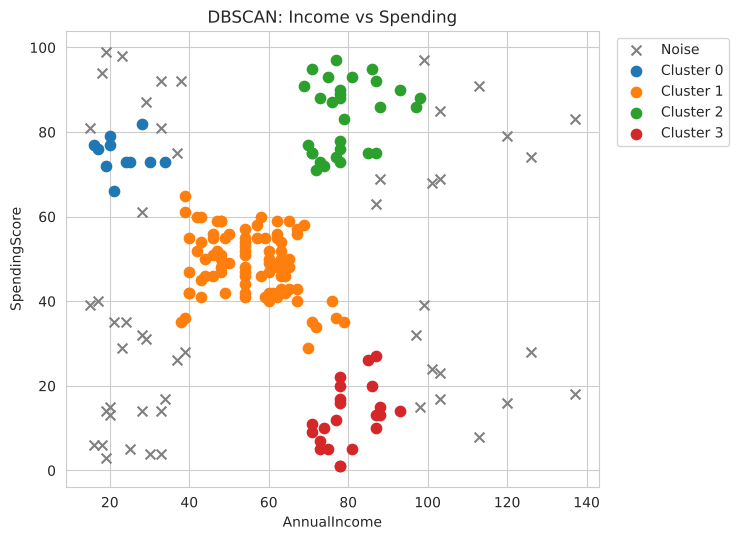

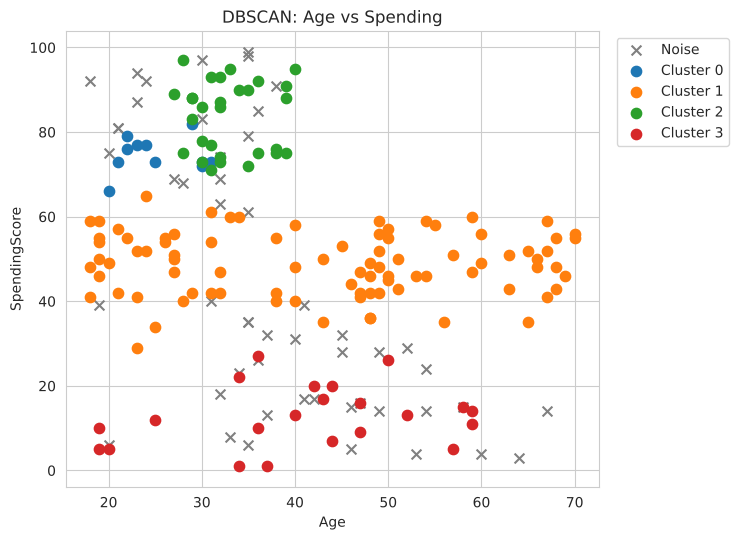

In [28]:
cluster_scatter('DBSCAN_Cluster', 'AnnualIncome', 'SpendingScore', 'DBSCAN: Income vs Spending', 'dbscan_income_spending.png')
cluster_scatter('DBSCAN_Cluster', 'Age', 'SpendingScore', 'DBSCAN: Age vs Spending', 'dbscan_age_spending.png')

In [29]:
core = df[df['DBSCAN_Cluster'] != -1]
db_profile = core.groupby('DBSCAN_Cluster')[num_cols].mean().round(1)
db_profile['Customers'] = core['DBSCAN_Cluster'].value_counts().sort_index()
db_profile = db_profile.sort_values('SpendingScore', ascending=False)
db_profile['Persona'] = [get_persona(r.AnnualIncome, r.SpendingScore) for r in db_profile.itertuples()]
display(db_profile)

noise = df[df['DBSCAN_Cluster'] == -1]
print('Noise profile')
print(noise[num_cols].mean().round(1))
print(noise['Gender'].value_counts())

,Age,AnnualIncome,SpendingScore,Customers,Persona
DBSCAN_Cluster,,,,,
2,32.9,79.2,83.6,29,Big Spenders
0,25.2,23.1,74.6,11,Young Aspirers
1,42.8,55.4,48.8,87,Average Shoppers
3,41.0,80.2,12.7,22,Careful Spenders


Noise profile
Age              37.5
AnnualIncome     58.3
SpendingScore    44.5
dtype: float64
Gender
Female    30
Male      21
Name: count, dtype: int64


**Noise shoppers:** their average profile (age 37.5, income 58.3k, spending score 44.5) is close to the overall average, so they are not extreme outliers. They are mostly shoppers sitting between segments or in the less dense parts of the plot. The Budget Shoppers group does not appear among the four DBSCAN clusters, so most of it falls into noise. The strict min_samples = 10 setting requires a very dense group, which the smaller segments cannot always provide.

## Step 6: Algorithm Comparison and Business Interpretation
### 6.1 Internal metrics

In [30]:
def scores(X, labels):
    mask = labels != -1
    return (silhouette_score(X[mask], labels[mask]),
            davies_bouldin_score(X[mask], labels[mask]),
            calinski_harabasz_score(X[mask], labels[mask]))

km_s = scores(X_2d_scaled, df['KMeans_Cluster'].values)
ag_s = scores(X_2d_scaled, df['Agg_Cluster'].values)
db_s = scores(X_2d_scaled, df['DBSCAN_Cluster'].values)

comparison = pd.DataFrame({
    'Algorithm': ['K-Means', f'Agglomerative ({best_link})', 'DBSCAN'],
    'Hyperparameters': [f'k={k_opt}', f'n_clusters={n_chosen}, linkage={best_link}', f'eps={best_eps}, min_samples={best_ms}'],
    'Clusters': [k_opt, n_chosen, n_clusters],
    'Silhouette': [km_s[0], ag_s[0], db_s[0]],
    'Davies-Bouldin': [km_s[1], ag_s[1], db_s[1]],
    'Calinski-Harabasz': [km_s[2], ag_s[2], db_s[2]],
    'Noise %': [0.0, 0.0, round(n_noise / len(df) * 100, 1)]
}).set_index('Algorithm')

comparison['Rank'] = (comparison['Silhouette'].rank(ascending=False) +
                      comparison['Davies-Bouldin'].rank(ascending=True) +
                      comparison['Calinski-Harabasz'].rank(ascending=False)) / 3
comparison.round(3)

,Hyperparameters,Clusters,Silhouette,Davies-Bouldin,Calinski-Harabasz,Noise %,Rank
Algorithm,,,,,,,
K-Means,k=5,5,0.555,0.572,248.649,0.0,2.0
Agglomerative (ward),"n_clusters=5, linkage=ward",5,0.554,0.578,244.410,0.0,3.0
DBSCAN,"eps=0.4, min_samples=10",4,0.597,0.473,263.612,25.5,1.0


**Ranking by metrics:** DBSCAN ranks first (silhouette 0.597, Davies-Bouldin 0.473, Calinski-Harabasz 263.6), K-Means second (0.555, 0.572, 248.6) and Hierarchical third (0.554, 0.578, 244.4).

This ranking needs care. The DBSCAN metrics are computed on only 74.5% of the customers and one persona is missing. K-Means and Hierarchical score almost the same and cover every customer. DBSCAN looks most compact on paper, but K-Means gives the most useful and complete segmentation.

### 6.2 K-Means stability

In [31]:
seeds = [0, 7, 21, 42, 99]
seed_scores = []
for s in seeds:
    km = KMeans(n_clusters=k_opt, init='k-means++', n_init=20, max_iter=500, random_state=s).fit(X_2d_scaled)
    seed_scores.append(silhouette_score(X_2d_scaled, km.labels_))

print(pd.DataFrame({'random_state': seeds, 'Silhouette': seed_scores}).round(4).to_string(index=False))
print(f'Mean: {np.mean(seed_scores):.4f} | Std: {np.std(seed_scores):.6f}')

 random_state  Silhouette
            0      0.5547
            7      0.5547
           21      0.5547
           42      0.5547
           99      0.5547
Mean: 0.5547 | Std: 0.000000


The silhouette score is 0.5547 on all five runs (std 0.000000), so the result is fully stable. The five groups are well separated and the 20 initialisations per run always reach the same solution.

### 6.3 Business recommendation

**To:** Retail Operations Director, Nexus Malls / Phoenix Marketcity

**Recommended algorithm: K-Means with k = 5.**
K-Means has a silhouette score of 0.555, a Davies-Bouldin index of 0.572 and a Calinski-Harabasz score of 248.6. It assigns every customer to a segment, gives the same result on every run, and matches the five groups visible in the data. Hierarchical clustering is almost identical (0.554, 0.578, 244.4, 98% agreement) and confirms the result. DBSCAN scores higher (0.597, 0.473, 263.6) but leaves 25.5% of customers unassigned and loses the Budget Shoppers group, so it is not suitable for planning.

**Segments and strategies**

| Segment | Customers | Description | Strategy |
|---|---|---|---|
| Big Spenders | 39 | High income (about 86k), high spending (82) | Premium lounge with curated luxury brand pop-ups near the food court, plus early access to new collections. |
| Careful Spenders | 35 | High income (about 88k), low spending (17) | Invite-only experience events and personalised offers on quality brands to raise their spending. |
| Average Shoppers | 81 | Mid income (about 55k), mid spending (50) | Mid-market anchor stores in the main walkways with seasonal sales and loyalty points. |
| Young Aspirers | 22 | Age 25, low income (about 26k), high spending (79) | Trend and fast-fashion zones with student discounts, social media contests and pop-up events. |
| Budget Shoppers | 23 | Low income (about 26k), low spending (21) | Value-for-money stores near the entrances and ₹50-off coupons through the mall app. |

**Data that would improve the segmentation**
- Purchase category and basket value per visit.
- Visit frequency and time spent in the mall from footfall sensors.
- Loyalty app behaviour such as coupon use and brand preferences.
- Postcode or travel distance to see where customers come from.

## Step 7: Pipeline and Deployment
### 7.1 Save the model and classify new shoppers

In [32]:
best_model = kmeans_2d
joblib.dump(scaler_2d, '../model/mall_scaler.pkl')
joblib.dump(best_model, '../model/mall_segmentation_model.pkl')

scaler = joblib.load('../model/mall_scaler.pkl')
model = joblib.load('../model/mall_segmentation_model.pkl')
centers = scaler.inverse_transform(model.cluster_centers_)
persona_map = {i: get_persona(c[0], c[1]) for i, c in enumerate(centers)}

def classify_shopper(age, annual_income, spending_score, gender=None):
    point = scaler.transform(pd.DataFrame([[annual_income, spending_score]], columns=feat_2d))
    label = int(model.predict(point)[0])
    return label, persona_map[label]

new_shoppers = [
    (22, 30, 85, 'Female'),
    (45, 95, 15, 'Male'),
    (31, 88, 90, 'Female'),
    (58, 20, 10, 'Male'),
    (35, 55, 50, 'Female'),
]

results = []
for age, income, score, gender in new_shoppers:
    label, persona = classify_shopper(age, income, score, gender)
    results.append({'Age': age, 'Income (k$)': income, 'Spending Score': score, 'Gender': gender, 'Cluster': label, 'Persona': persona})
pd.DataFrame(results)

,Age,Income (k$),Spending Score,Gender,Cluster,Persona
0,22,30,85,Female,2,Young Aspirers
1,45,95,15,Male,3,Careful Spenders
2,31,88,90,Female,1,Big Spenders
3,58,20,10,Male,4,Budget Shoppers
4,35,55,50,Female,0,Average Shoppers


The saved model is the 2D K-Means model, so `classify_shopper()` uses income and spending score to choose the cluster. Age and gender are accepted as inputs but do not change the result. Each of the five test shoppers lands in the persona that matches their profile.